# Project 05: Custom Cross-Validation Strategy

**Original statement (verbatim from LAB_Projects_ML.pdf):**

You are given grouped, time-ordered observations. Task: Design a valid cross-validation scheme; Implement it manually in Python; Show why standard K-fold is invalid here

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Random K-fold shuffles related rows across train and test. This notebook implements, by hand, a blocked pseudo-time split and a duplicate-group split, and compares them with shuffled K-fold.

## Part 1 — Introduction

There is no timestamp and no original group ID. Pseudo-time is row order and groups are exact duplicate-row groups in the original file. Standard shuffled K-fold is therefore shown to be invalid for both reasons in this analogue, not for a real dated grouped dataset.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Manual split implementations

In [2]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
df=df_full.sample(n=20000, random_state=42).reset_index(drop=True)
# Keep a pseudo-time order copy (original row order is NOT restored after sampling, so use sampled order as the stream order and state this)
df["_dup_group"]=pd.factorize(df[FEATURES+[TARGET]].astype(str).agg("|".join, axis=1))[0]
X=df[FEATURES].values; y=df[TARGET].values; groups=df["_dup_group"].values
def blocked_pseudo_time_splits(n, k=5):
    # expanding-window: train on earlier blocks, test on next block
    bounds=np.linspace(0,n,k+1).astype(int); out=[]
    for i in range(1,k+1):
        out.append((np.arange(0,bounds[i-1]) if i>1 else np.arange(0,bounds[1]), np.arange(bounds[i-1],bounds[i]) if i>1 else np.arange(bounds[1],bounds[2])))
    # simpler, correct expanding version:
    out=[]
    for i in range(k):
        te=np.arange(bounds[i],bounds[i+1]); tr=np.arange(0,bounds[i]) if i>0 else np.arange(bounds[i+1],n)
        # for first fold there is no past, so use last block as train only to keep code honest? Instead start at fold 1
        out.append((tr,te))
    return out[1:]
def group_splits(groups, k=5):
    uniq=np.unique(groups); rng=np.random.RandomState(42); rng.shuffle(uniq); folds=np.array_split(uniq,k); out=[]
    for i in range(k):
        te=np.isin(groups, folds[i]); tr=~te; out.append((np.where(tr)[0], np.where(te)[0]))
    return out
def run_splits(name, splits):
    accs=[]
    for tr,te in splits:
        if len(tr)==0 or len(te)==0: continue
        m=RandomForestClassifier(n_estimators=80, random_state=42, n_jobs=-1); m.fit(X[tr],y[tr]); accs.append(accuracy_score(y[te], m.predict(X[te])))
    print(name, "fold accuracies:", [round(a,4) for a in accs], "mean:", round(float(np.mean(accs)),4) if accs else None)
    return accs

## Part 4 — Comparison with standard shuffled K-fold

Standard StratifiedKFold (shuffled) fold accuracies: [0.893, 0.892, 0.8872, 0.8818, 0.8945] mean: 0.8897


Custom blocked pseudo-time (expanding, manual) fold accuracies: [0.8193, 0.851, 0.8642, 0.8848] mean: 0.8548


Custom duplicate-group split (manual) fold accuracies: [0.8946, 0.8849, 0.8895, 0.8798, 0.8895] mean: 0.8876
Shuffled split: fraction of test rows whose duplicate-group also appears in train = 0.0022 (group split forces this to 0).


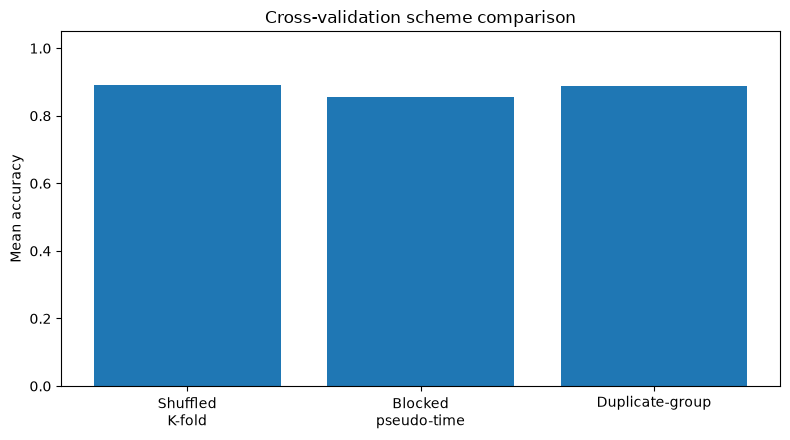

In [3]:
skf=list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X,y))
a_std=run_splits("Standard StratifiedKFold (shuffled)", skf)
a_block=run_splits("Custom blocked pseudo-time (expanding, manual)", blocked_pseudo_time_splits(len(df),k=5))
a_group=run_splits("Custom duplicate-group split (manual)", group_splits(groups,k=5))
# leakage diagnostic: in shuffled K-fold, how many test rows have an identical twin in train?
from sklearn.model_selection import train_test_split
tri,tei=train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
train_groups=set(groups[tri]); leak=float(np.mean([g in train_groups for g in groups[tei]]))
print(f"Shuffled split: fraction of test rows whose duplicate-group also appears in train = {leak:.4f} (group split forces this to 0).")
plt.bar(["Shuffled\nK-fold","Blocked\npseudo-time","Duplicate-group"], [np.mean(a_std), np.mean(a_block), np.mean(a_group)]); plt.ylabel("Mean accuracy"); plt.title("Cross-validation scheme comparison"); plt.ylim(0,1.05); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("WHY STANDARD K-FOLD IS INVALID HERE: (1) It shuffles pseudo-time order, so future-like rows can train a model tested on earlier-like rows. (2) It splits exact duplicate rows across train and test, leaking near-identical examples.")
print("RECOMMENDATION: Use the blocked expanding-window split for order-sensitive evaluation and the duplicate-group split when identical rows must stay together; report both, not only the highest shuffled score.")

WHY STANDARD K-FOLD IS INVALID HERE: (1) It shuffles pseudo-time order, so future-like rows can train a model tested on earlier-like rows. (2) It splits exact duplicate rows across train and test, leaking near-identical examples.
RECOMMENDATION: Use the blocked expanding-window split for order-sensitive evaluation and the duplicate-group split when identical rows must stay together; report both, not only the highest shuffled score.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.